In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
TARGET = "covid_vaccine"

In [ ]:
data=pd.read_csv("/content/drive/MyDrive/dataset_C_training.csv")

In [ ]:
data

,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4751,4752,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,NaN,...,"MSA, Not Principle City",1.0,2.0,0,2,1,1.0,transportation,0,0
4752,4753,2.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Not Principle City",0.0,1.0,0,4,4,1.0,government,1,0
4753,4754,3.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Not Principle City",1.0,0.0,0,5,3,2.0,healthcare,0,1
4754,4755,1.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",0.0,0.0,0,4,1,1.0,NaN,1,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance               2848 non-null   f

In [ ]:
data.shape          # (rows, columns)
      # dtypes, non-null counts, memory usage
data.dtypes         # just column types
data.columns.tolist()  # column names

['respondent_id',
 'covid_concern',
 'covid_knowledge',
 'behavioral_antiviral_meds',
 'behavioral_avoidance',
 'behavioral_face_mask',
 'behavioral_wash_hands',
 'behavioral_large_gatherings',
 'behavioral_outside_home',
 'behavioral_touch_face',
 'child_under_6_months',
 'health_worker',
 'health_insurance',
 'age_group',
 'education',
 'race',
 'sex',
 'income_poverty',
 'marital_status',
 'rent_or_own',
 'employment_status',
 'census_msa',
 'household_adults',
 'household_children',
 'doctor_recc_covid',
 'opinion_covid_vacc_effective',
 'opinion_covid_risk',
 'opinion_covid_sick_from_vacc',
 'employment_sector',
 'number_chronic_med_conditions',
 'covid_vaccine']

In [ ]:
data.describe()                # numeric columns
data.describe(include='all')   # all columns (incl. categorical)

,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
count,4756.00000,4744.000000,4729.000000,4742.000000,4729.000000,4754.000000,4747.000000,4746.000000,4742.000000,4735.000000,...,4756,4717.000000,4717.000000,4756.000000,4756.000000,4756.000000,4666.000000,2426,4756.000000,4756.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,NaN,NaN,NaN,21,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"MSA, Not Principle City",NaN,NaN,NaN,NaN,NaN,NaN,healthcare,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2104,NaN,NaN,NaN,NaN,NaN,NaN,527,NaN,NaN
mean,2378.50000,1.648609,1.296469,0.053353,0.733347,0.072991,0.839267,0.356300,0.329186,0.693981,...,NaN,0.893576,0.532542,0.227502,3.812447,2.489277,2.121732,NaN,0.379731,0.326745
std,1373.08327,0.903204,0.615705,0.224760,0.442256,0.260149,0.367323,0.478956,0.469967,0.460886,...,NaN,0.763981,0.934933,0.419263,1.051633,1.261286,1.335704,NaN,0.670265,0.469073
min,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,0.000000,0.000000
25%,1189.75000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,0.000000,0.000000,0.000000,3.000000,1.000000,1.000000,NaN,0.000000,0.000000
50%,2378.50000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,...,NaN,1.000000,0.000000,0.000000,4.000000,2.000000,2.000000,NaN,0.000000,0.000000
75%,3567.25000,2.000000,2.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,NaN,1.000000,1.000000,0.000000,4.000000,4.000000,4.000000,NaN,1.000000,1.000000


In [ ]:
data.isnull().sum()                    # count NaNs per column
data.isnull().sum() / len(data) * 100  # % missing

,0
respondent_id,0.000000
covid_concern,0.252313
covid_knowledge,0.567704
behavioral_antiviral_meds,0.294365
behavioral_avoidance,0.567704
behavioral_face_mask,0.042052
behavioral_wash_hands,0.189235
behavioral_large_gatherings,0.210261
behavioral_outside_home,0.294365
behavioral_touch_face,0.441548


In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.corr(numeric_only=True)

,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,health_worker,health_insurance,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,number_chronic_med_conditions,covid_vaccine
respondent_id,1.000000,-0.001993,0.004841,0.016096,0.010127,0.003456,-0.027442,-0.005593,-0.005674,-0.012465,...,0.030545,0.014983,-0.007994,-0.016465,0.008885,0.014692,0.017897,-0.012825,0.020061,0.024270
covid_concern,-0.001993,1.000000,0.060691,0.104023,0.229567,0.143436,0.280016,0.253713,0.240684,0.253159,...,0.037704,0.015742,-0.010690,0.041777,0.119956,0.212684,0.352838,0.224461,0.064928,0.135191
covid_knowledge,0.004841,0.060691,1.000000,-0.014191,0.092638,0.030783,0.083971,-0.051215,-0.047252,0.097073,...,0.198313,0.098137,0.014050,0.044011,0.102678,0.153734,0.138100,-0.086446,-0.011802,0.164260
behavioral_antiviral_meds,0.016096,0.104023,-0.014191,1.000000,0.075548,0.102945,0.067734,0.103919,0.124652,0.078729,...,-0.000701,-0.058983,0.074951,0.101758,0.034540,-0.003184,0.083050,0.094076,0.004156,0.010825
behavioral_avoidance,0.010127,0.229567,0.092638,0.075548,1.000000,0.069826,0.330480,0.204926,0.200816,0.320014,...,-0.006763,0.029535,0.029147,0.047427,0.066063,0.120234,0.122868,0.093887,0.035954,0.068290
behavioral_face_mask,0.003456,0.143436,0.030783,0.102945,0.069826,1.000000,0.087584,0.173085,0.160734,0.088124,...,0.085202,0.012865,0.014635,0.008682,0.050191,0.012995,0.095690,0.079207,0.059330,0.037320
behavioral_wash_hands,-0.027442,0.280016,0.083971,0.067734,0.330480,0.087584,1.000000,0.173400,0.168645,0.364554,...,0.065099,0.047161,0.006916,0.050481,0.070978,0.137390,0.196854,0.088378,0.001679,0.075328
behavioral_large_gatherings,-0.005593,0.253713,-0.051215,0.103919,0.204926,0.173085,0.173400,1.000000,0.576961,0.238409,...,-0.051464,-0.048619,-0.030314,-0.000481,0.063824,0.052552,0.102555,0.138865,0.087932,0.008797
behavioral_outside_home,-0.005674,0.240684,-0.047252,0.124652,0.200816,0.160734,0.168645,0.576961,1.000000,0.255749,...,-0.031935,-0.053121,-0.026065,-0.010010,0.034391,0.043100,0.103925,0.141796,0.075328,0.016675
behavioral_touch_face,-0.012465,0.253159,0.097073,0.078729,0.320014,0.088124,0.364554,0.238409,0.255749,1.000000,...,0.078709,0.024682,-0.000834,0.032644,0.097634,0.120362,0.180498,0.086401,0.023191,0.097420


In [ ]:
df = data.drop(columns=["respondent_id"]).copy()

# Normalize double-spaces / stray whitespace that appear in census_msa etc.
obj_cols = df.select_dtypes(include="object").columns
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    df[c] = df[c].replace({"nan": np.nan})   # restore real NaNs

print("Shape:", df.shape)
df.isnull().mean().sort_values(ascending=False).head(10)

Shape: (4756, 30)


,0
employment_sector,0.489907
health_insurance,0.401177
income_poverty,0.157275
rent_or_own,0.069176
employment_status,0.050042
marital_status,0.048570
education,0.047939
child_under_6_months,0.028385
health_worker,0.027754
opinion_covid_sick_from_vacc,0.018923


In [ ]:
binary_cols = [
    "health_worker", "child_under_6_months",
    "behavioral_antiviral_meds", "behavioral_avoidance", "behavioral_face_mask",
    "behavioral_wash_hands", "behavioral_large_gatherings",
    "behavioral_outside_home", "behavioral_touch_face",
    "health_insurance",
]

scale_cols = [
    "covid_concern", "covid_knowledge",
    "opinion_covid_vacc_effective", "opinion_covid_risk",
    "opinion_covid_sick_from_vacc",
]

count_cols = ["household_adults", "household_children",
              "number_chronic_med_conditions"]

low_miss_cat = ["education", "marital_status", "rent_or_own", "employment_status"]
high_miss_cat = ["employment_sector", "income_poverty"]

# 1) binary → mode
for c in binary_cols:
    df[c] = df[c].fillna(df[c].mode()[0]).astype(int)

# 2) scales → median
for c in scale_cols:
    df[c] = df[c].fillna(df[c].median())

# 3) counts → median
for c in count_cols:
    df[c] = df[c].fillna(df[c].median())

# 4) low-miss categoricals → mode
for c in low_miss_cat:
    df[c] = df[c].fillna(df[c].mode()[0])

# 5) high-miss categoricals → "Unknown" (missingness is potentially informative)
for c in high_miss_cat:
    df[c] = df[c].fillna("Unknown")

# Sanity check
assert df.isnull().sum().sum() == 0, "Still have NaNs!"
print("✅ All missing values handled. Shape:", df.shape)

✅ All missing values handled. Shape: (4756, 30)


In [ ]:
age_map = {
    "18 - 24 Years": 1, "25 - 34 Years": 2, "35 - 44 Years": 3,
    "45 - 54 Years": 4, "55 - 64 Years": 5, "65+ Years":     6,
}

edu_map = {
    "Less than 12 years":   1,
    "12 years":             2,
    "Some college":         3,
    "College graduate":     4,
}

inc_map = {
    "Below Poverty":                     1,
    "< $75,000, Above Poverty":          2,
    "> $75,000":                         3,
    "Unknown":                           2,   # treat as mid‑range
}

# Apply — using .map with a fallback to protect against typos
df["age_group"]      = df["age_group"].map(age_map).fillna(3).astype(int)
df["education"]      = df["education"].map(edu_map).fillna(2).astype(int)
df["income_poverty"] = df["income_poverty"].map(inc_map).fillna(2).astype(int)

df[["age_group", "education", "income_poverty"]].describe()

,age_group,education,income_poverty
count,4756.000000,4756.0,4756.000000
mean,4.378469,2.0,2.175988
std,1.191519,0.0,0.581108
min,3.000000,2.0,1.000000
25%,3.000000,2.0,2.000000
50%,4.000000,2.0,2.000000
75%,6.000000,2.0,3.000000
max,6.000000,2.0,3.000000


In [ ]:
msa_map = {
    "MSA, Principle City":      3,
    "MSA, Not Principle City":  2,
    "Non-MSA":                  1,
}
df["census_msa"] = df["census_msa"].map(msa_map).fillna(1).astype(int)

In [ ]:
nominal_cats = ["race", "sex", "marital_status",
                "rent_or_own", "employment_status", "employment_sector"]

df = pd.get_dummies(df, columns=nominal_cats, drop_first=True, dtype=int)

print("Shape after encoding:", df.shape)
print("Object dtypes remaining:",
      df.select_dtypes(include="object").columns.tolist())


Shape after encoding: (4756, 53)
Object dtypes remaining: []


Data Visualization

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Drop the identifier for EDA
df = data.drop(columns=["respondent_id"]).copy()
TARGET = "covid_vaccine"

print("Overall vaccination rate: {:.2%}".format(df[TARGET].mean()))
print(df[TARGET].value_counts())

Overall vaccination rate: 32.67%
covid_vaccine
0    3202
1    1554
Name: count, dtype: int64


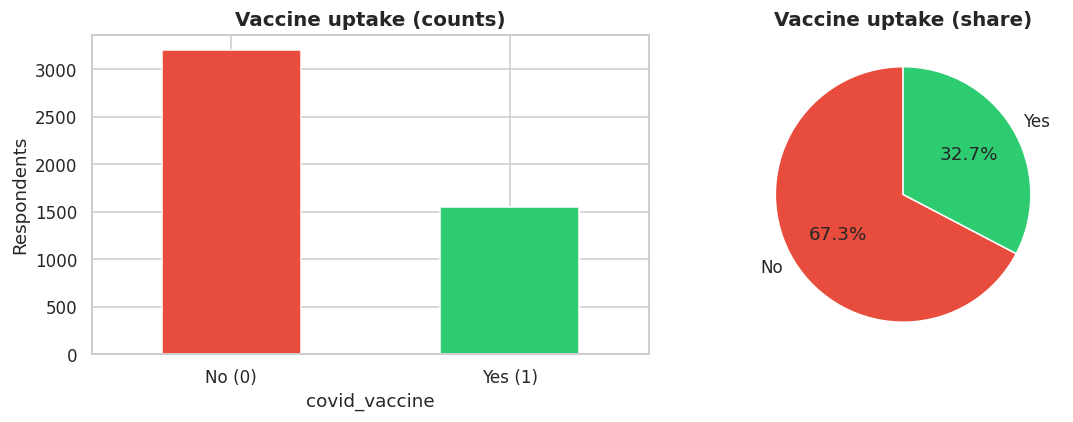

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

df[TARGET].value_counts().plot.bar(ax=ax[0], color=["#e74c3c", "#2ecc71"])
ax[0].set_title("Vaccine uptake (counts)")
ax[0].set_xticklabels(["No (0)", "Yes (1)"], rotation=0)
ax[0].set_ylabel("Respondents")

df[TARGET].value_counts(normalize=True).plot.pie(
    ax=ax[1], autopct="%1.1f%%", labels=["No", "Yes"],
    colors=["#e74c3c", "#2ecc71"], startangle=90
)
ax[1].set_ylabel("")
ax[1].set_title("Vaccine uptake (share)")

plt.tight_layout(); plt.show()

/tmp/ipykernel_361/3745004632.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=miss.values * 100, y=miss.index, palette="rocket")


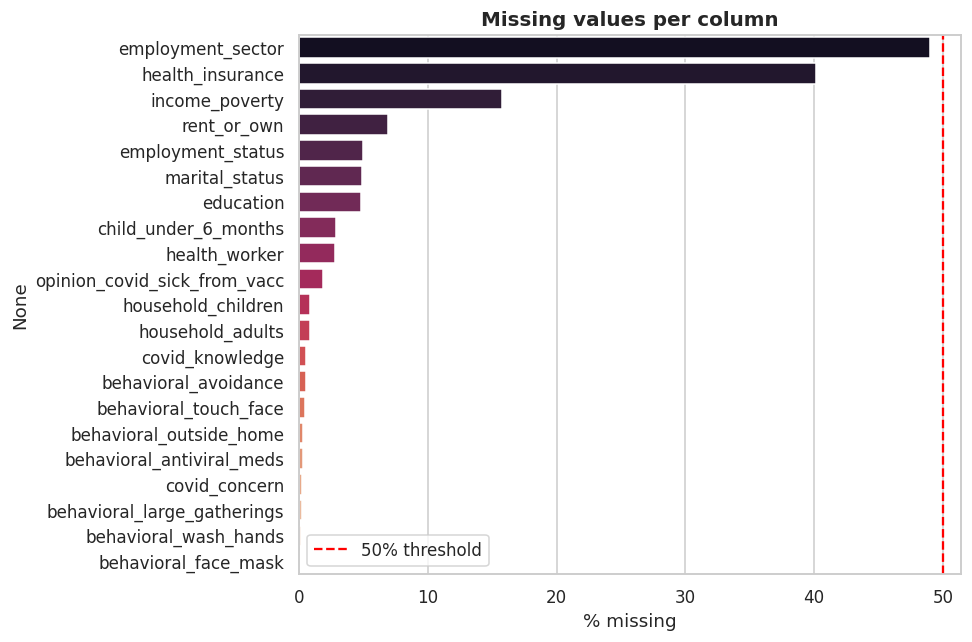

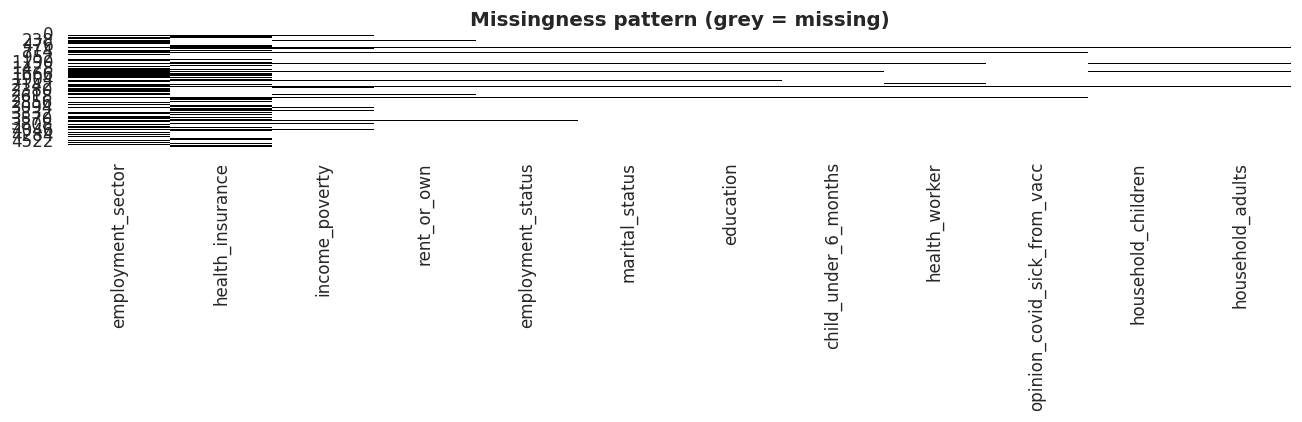

In [ ]:
miss = df.isnull().mean().sort_values(ascending=False)
miss = miss[miss > 0]

plt.figure(figsize=(9, 6))
sns.barplot(x=miss.values * 100, y=miss.index, palette="rocket")
plt.axvline(50, color="red", linestyle="--", label="50% threshold")
plt.xlabel("% missing")
plt.title("Missing values per column")
plt.legend()
plt.tight_layout(); plt.show()

# Missingness heatmap (top 12 columns)
top_miss = miss.head(12).index.tolist()
plt.figure(figsize=(12, 4))
sns.heatmap(df[top_miss].isnull(), cbar=False, cmap="gray_r")
plt.title("Missingness pattern (grey = missing)")
plt.tight_layout(); plt.show()

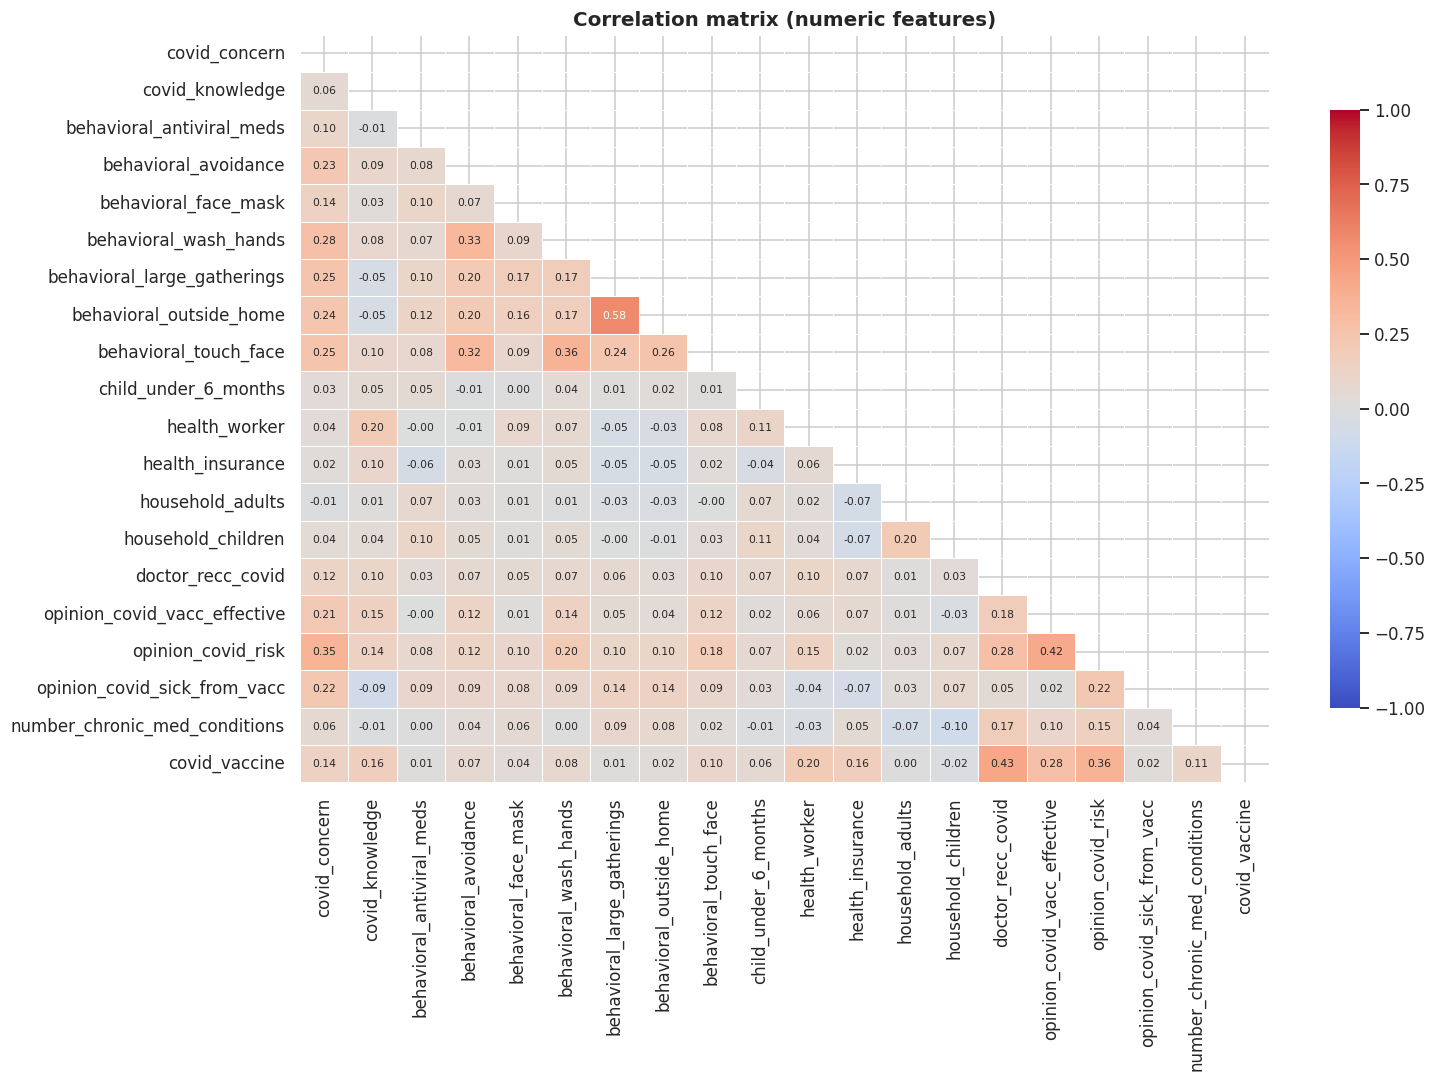

In [ ]:
num_cols = df.select_dtypes(include="number").columns
corr = df[num_cols].corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, cbar_kws={"shrink": .8},
            annot_kws={"size": 7}, linewidths=0.4)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout(); plt.show()

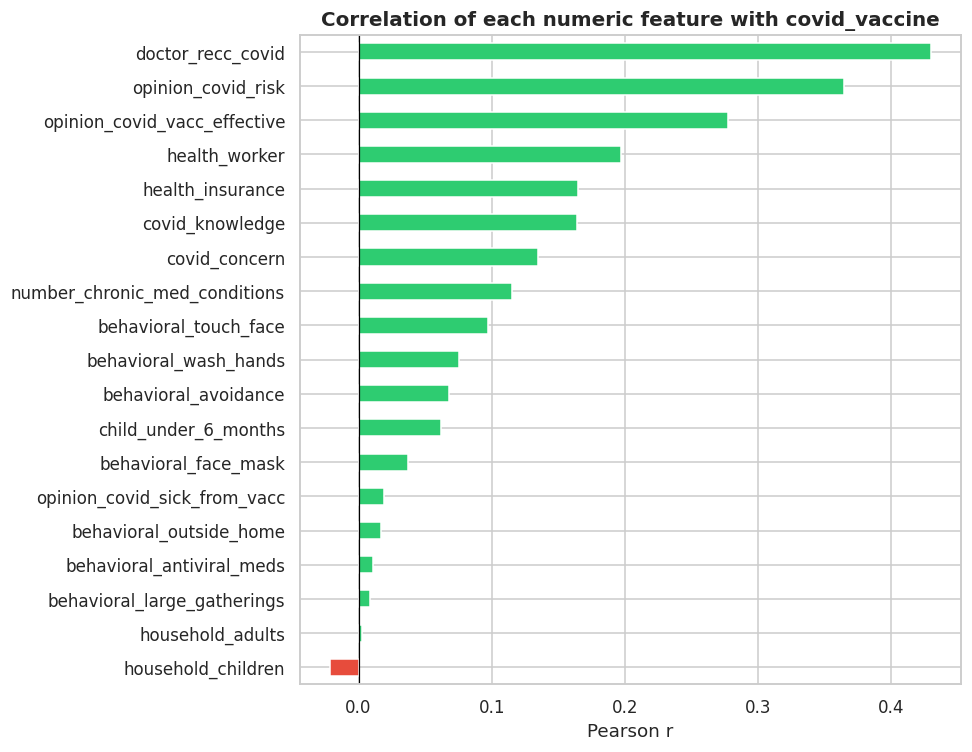

In [ ]:
target_corr = corr[TARGET].drop(TARGET).sort_values()

plt.figure(figsize=(9, 7))
colors = ["#e74c3c" if v < 0 else "#2ecc71" for v in target_corr.values]
target_corr.plot.barh(color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Correlation of each numeric feature with {TARGET}")
plt.xlabel("Pearson r")
plt.tight_layout(); plt.show()

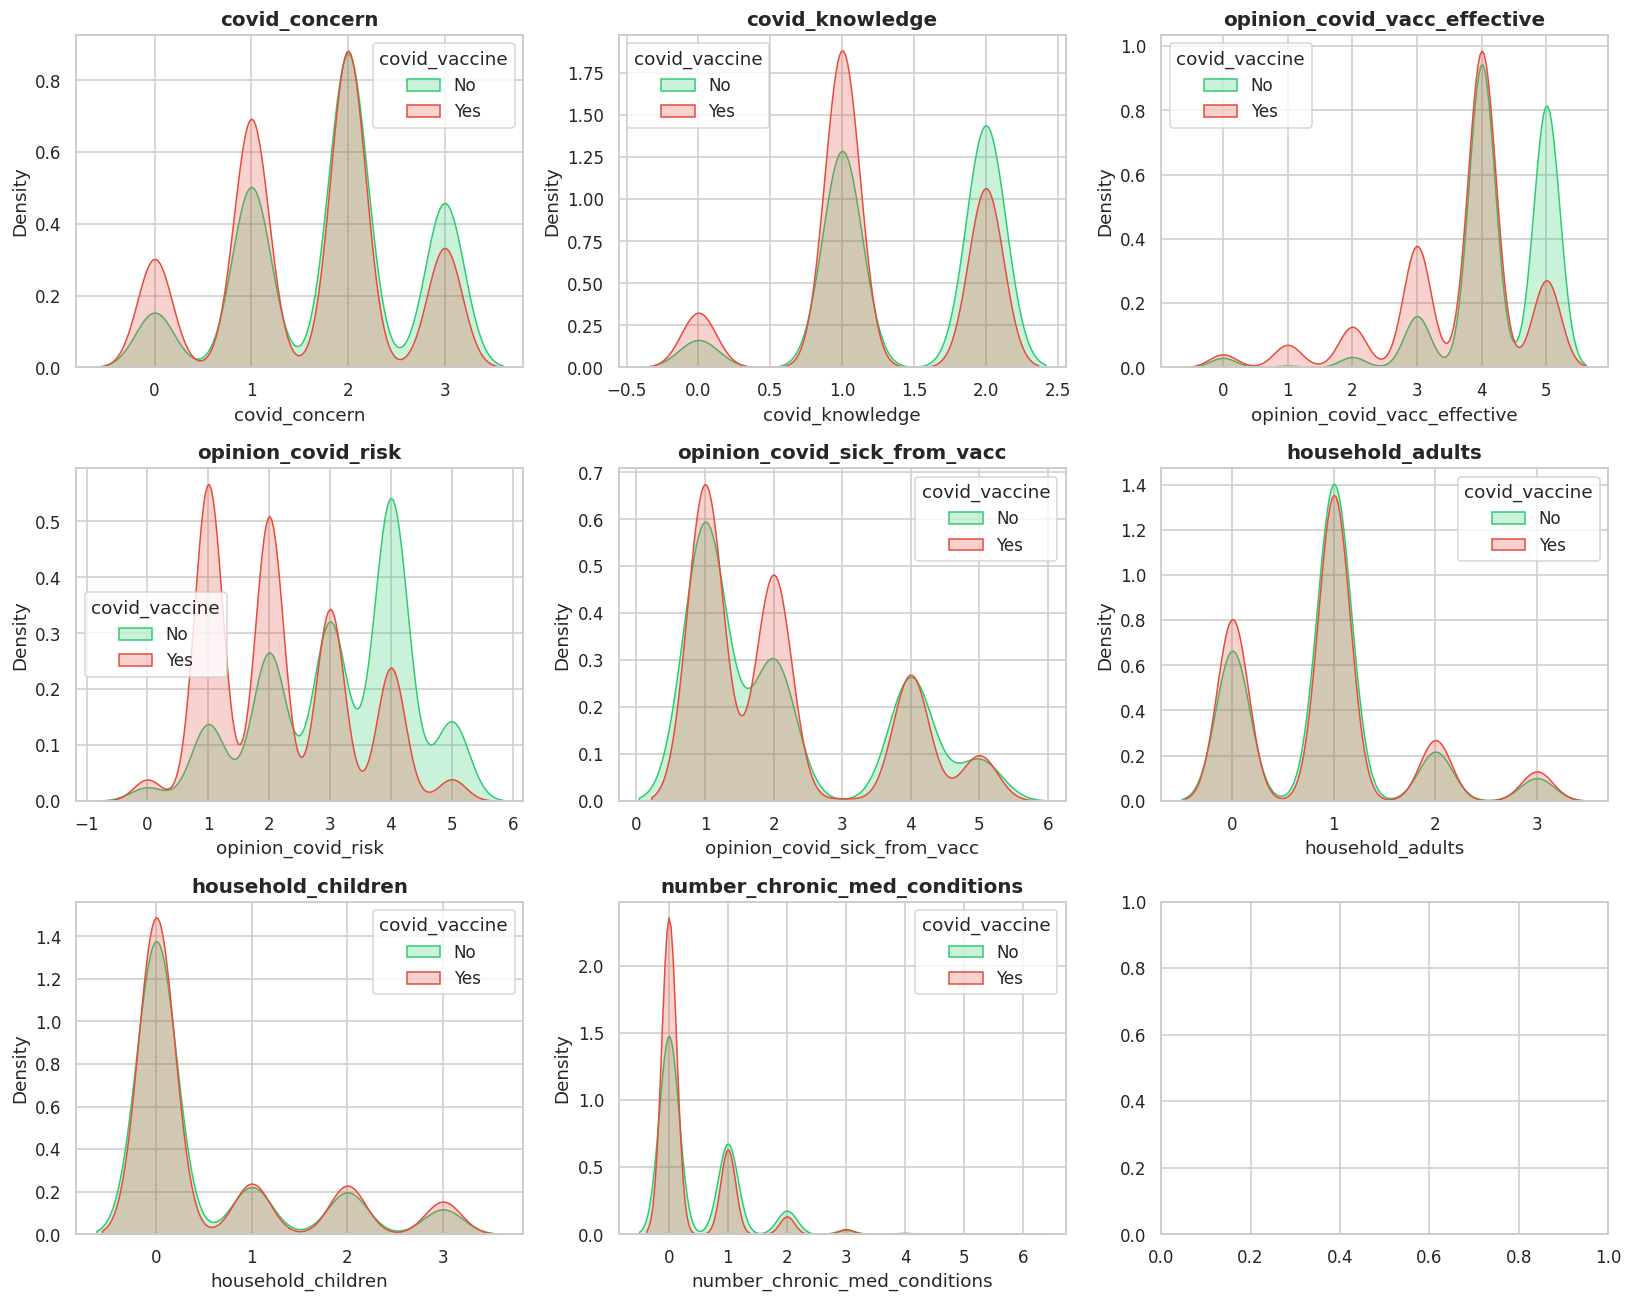

In [ ]:
num_features = ["covid_concern", "covid_knowledge",
                "opinion_covid_vacc_effective", "opinion_covid_risk",
                "opinion_covid_sick_from_vacc",
                "household_adults", "household_children",
                "number_chronic_med_conditions"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, num_features):
    sns.kdeplot(data=df, x=col, hue=TARGET, fill=True,
                common_norm=False, palette={0: "#e74c3c", 1: "#2ecc71"}, ax=ax)
    ax.set_title(col)
    ax.legend(title=TARGET, labels=["No", "Yes"])
plt.tight_layout(); plt.show()

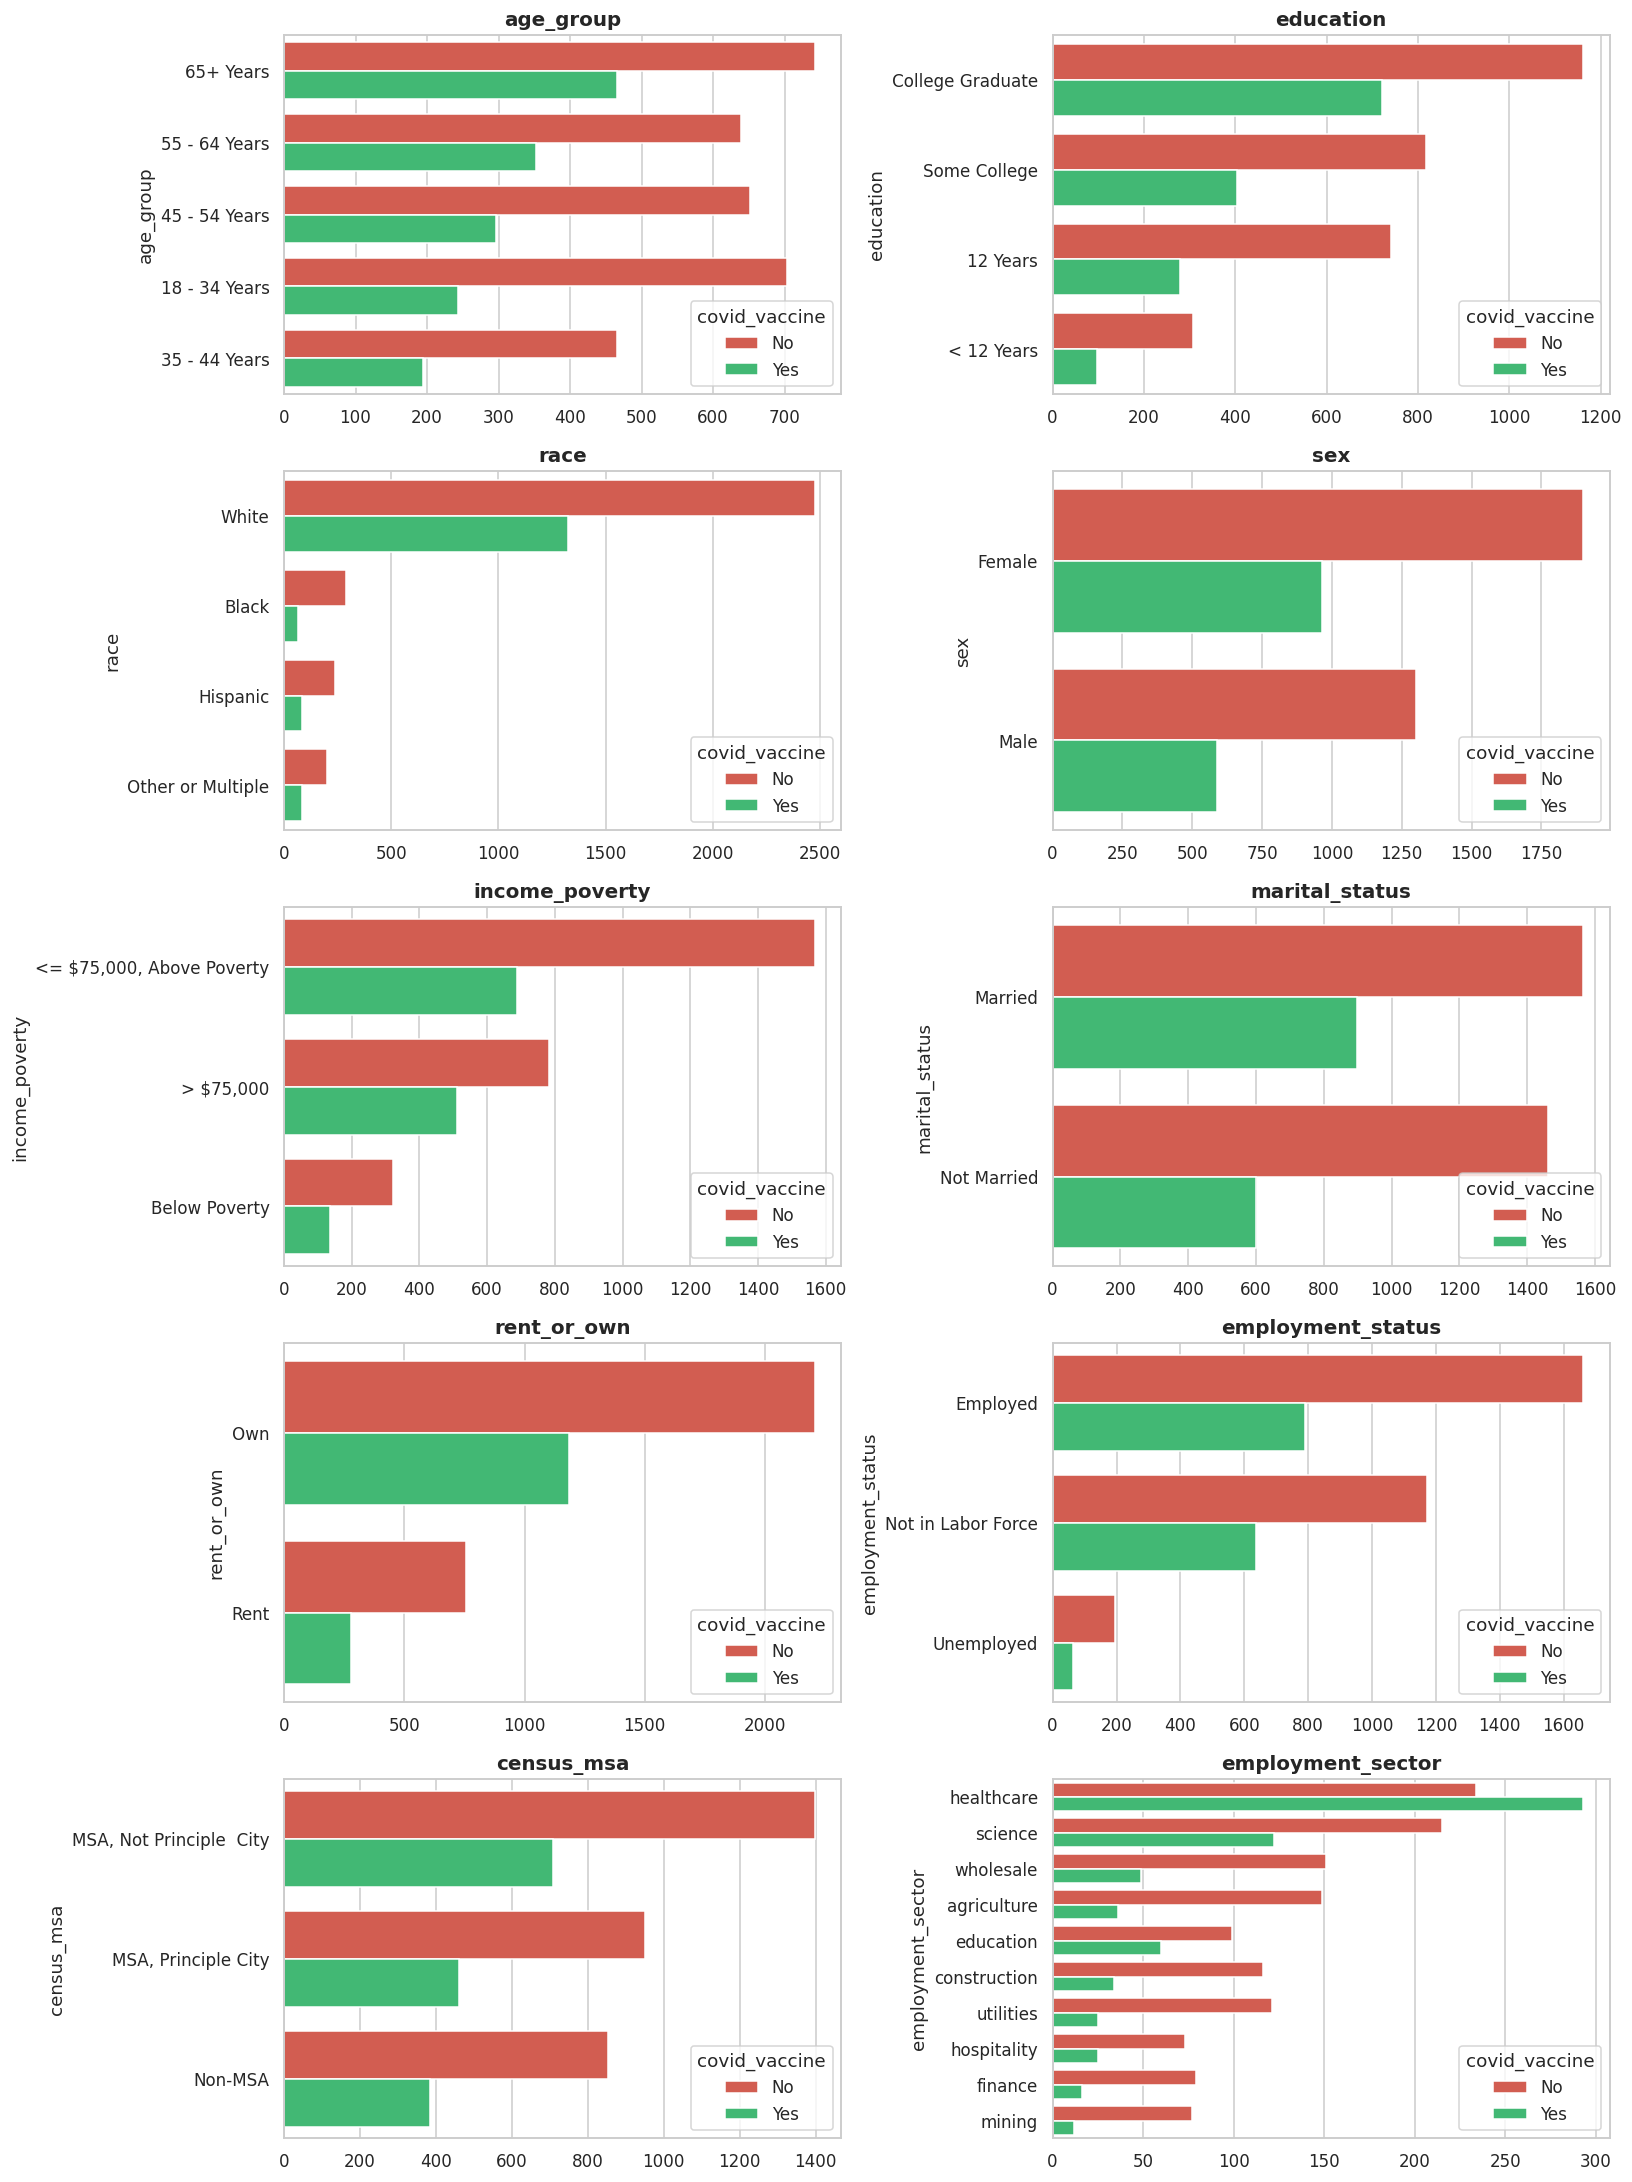

In [ ]:
cat_features = ["age_group", "education", "race", "sex",
                "income_poverty", "marital_status", "rent_or_own",
                "employment_status", "census_msa", "employment_sector"]

fig, axes = plt.subplots(5, 2, figsize=(15, 20))
for ax, col in zip(axes.flat, cat_features):
    order = df[col].value_counts().index[:10]
    sns.countplot(data=df, y=col, hue=TARGET, order=order,
                  palette={0: "#e74c3c", 1: "#2ecc71"}, ax=ax)
    ax.set_title(col)
    ax.legend(title=TARGET, labels=["No", "Yes"], loc="lower right")
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

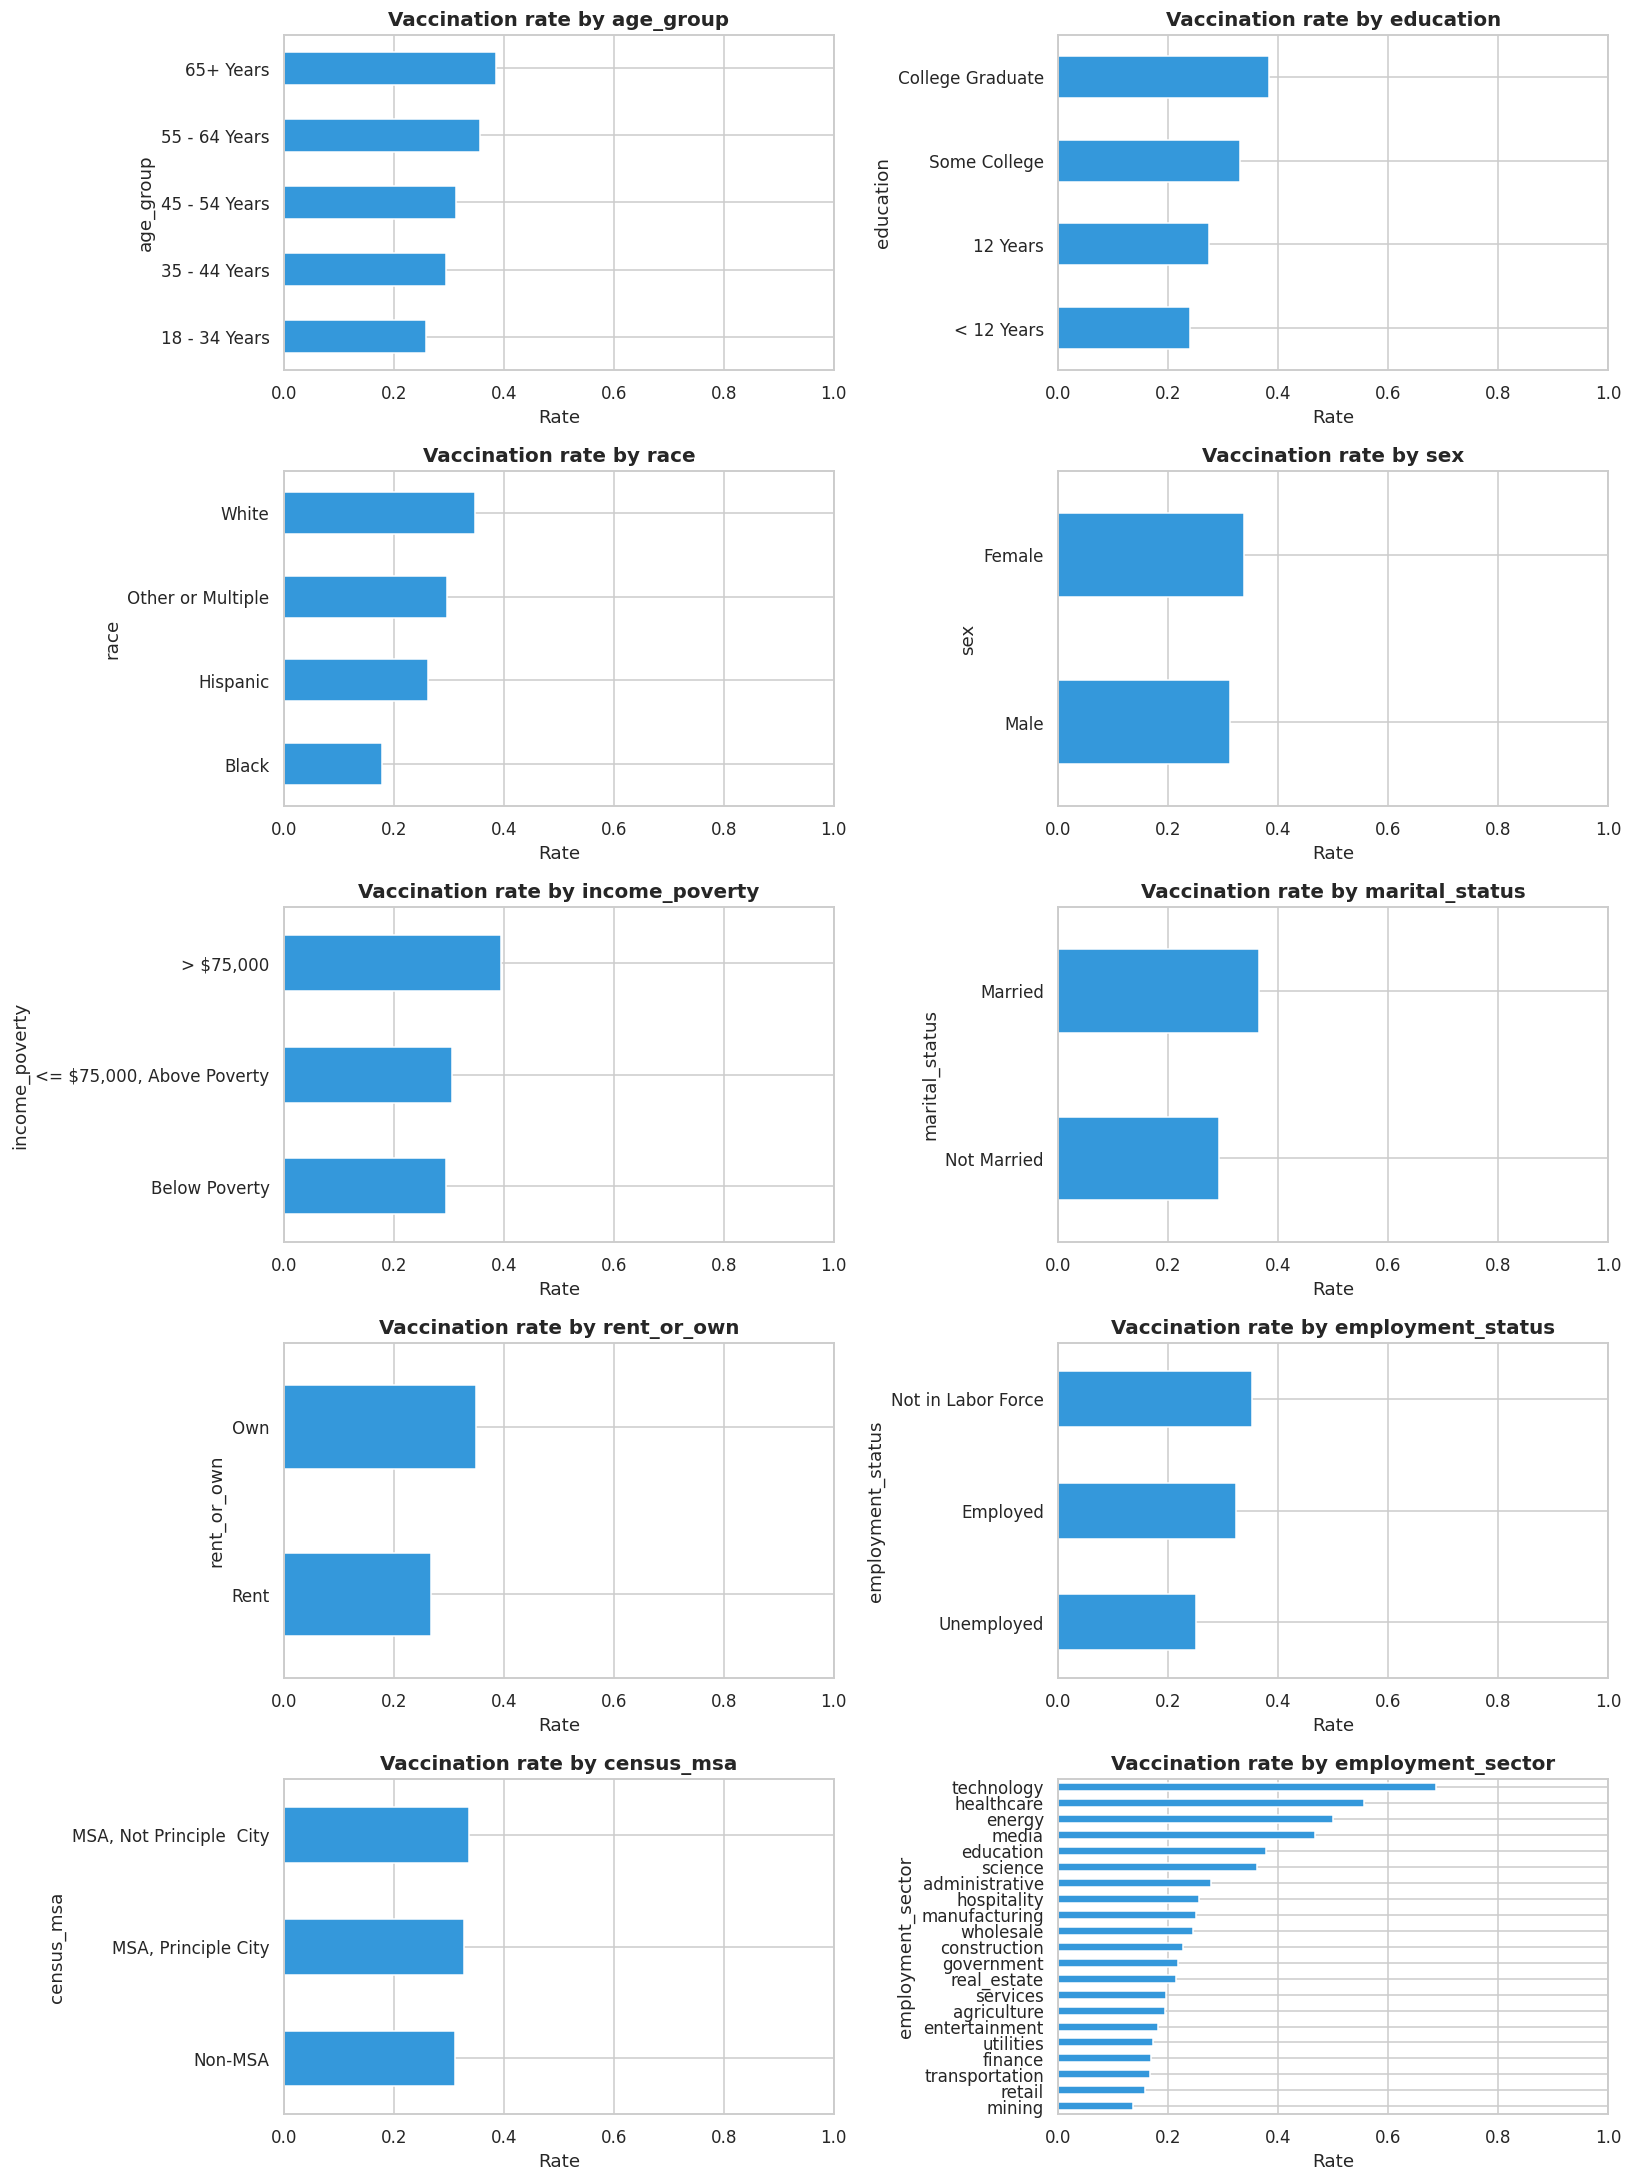

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(15, 20))
for ax, col in zip(axes.flat, cat_features):
    rates = df.groupby(col)[TARGET].mean().sort_values()
    rates.plot.barh(ax=ax, color="#3498db")
    ax.set_title(f"Vaccination rate by {col}")
    ax.set_xlabel("Rate")
    ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

/tmp/ipykernel_361/3687257626.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(["No rec", "Rec"])


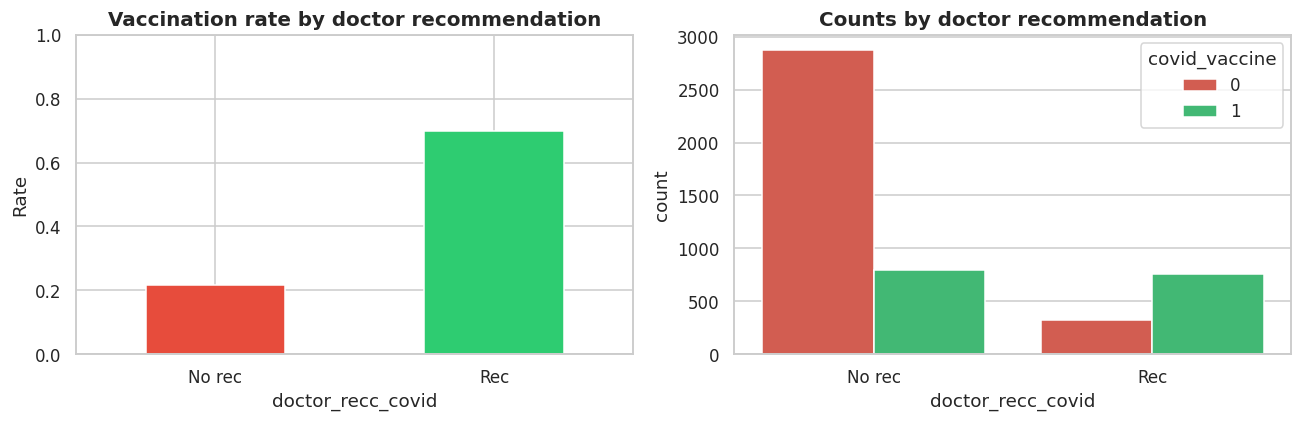

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df.groupby("doctor_recc_covid")[TARGET].mean().plot.bar(
    ax=ax[0], color=["#e74c3c", "#2ecc71"])
ax[0].set_title("Vaccination rate by doctor recommendation")
ax[0].set_xticklabels(["No rec", "Rec"], rotation=0)
ax[0].set_ylabel("Rate")
ax[0].set_ylim(0, 1)

sns.countplot(data=df, x="doctor_recc_covid", hue=TARGET,
              palette={0: "#e74c3c", 1: "#2ecc71"}, ax=ax[1])
ax[1].set_title("Counts by doctor recommendation")
ax[1].set_xticklabels(["No rec", "Rec"])
plt.tight_layout(); plt.show()

/tmp/ipykernel_361/1092642109.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x=c, y=TARGET, ax=a,
/tmp/ipykernel_361/1092642109.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x=c, y=TARGET, ax=a,
/tmp/ipykernel_361/1092642109.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x=c, y=TARGET, ax=a,


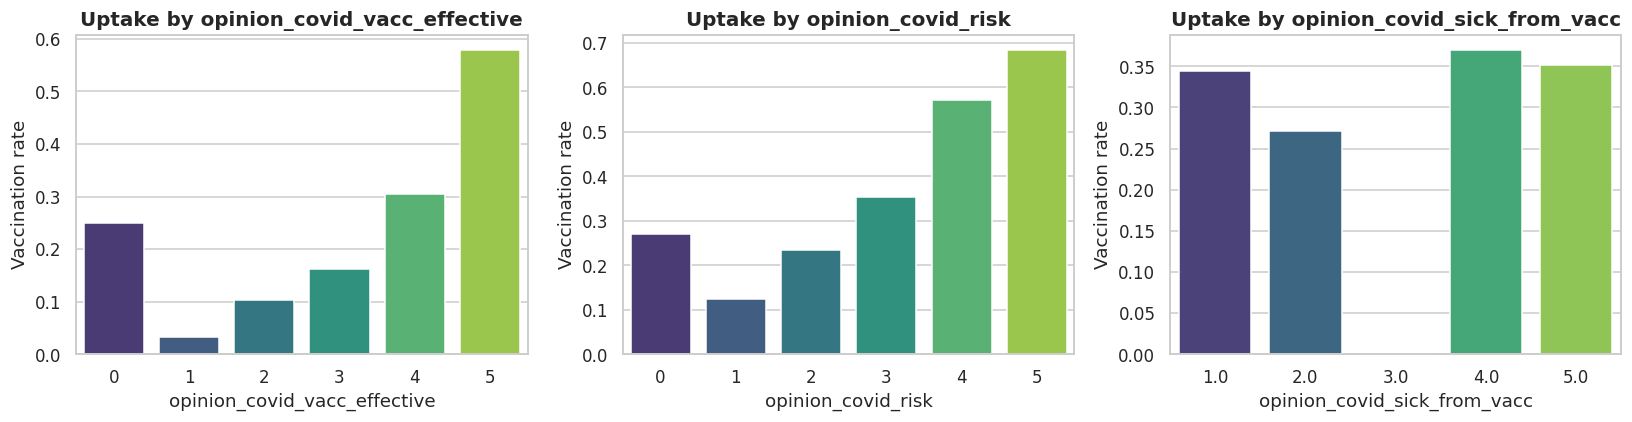

In [ ]:
opinion_cols = ["opinion_covid_vacc_effective", "opinion_covid_risk",
                "opinion_covid_sick_from_vacc"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, opinion_cols):
    sns.barplot(data=df, x=c, y=TARGET, ax=a,
                palette="viridis", errorbar=None)
    a.set_title(f"Uptake by {c}")
    a.set_ylabel("Vaccination rate")
plt.tight_layout(); plt.show()

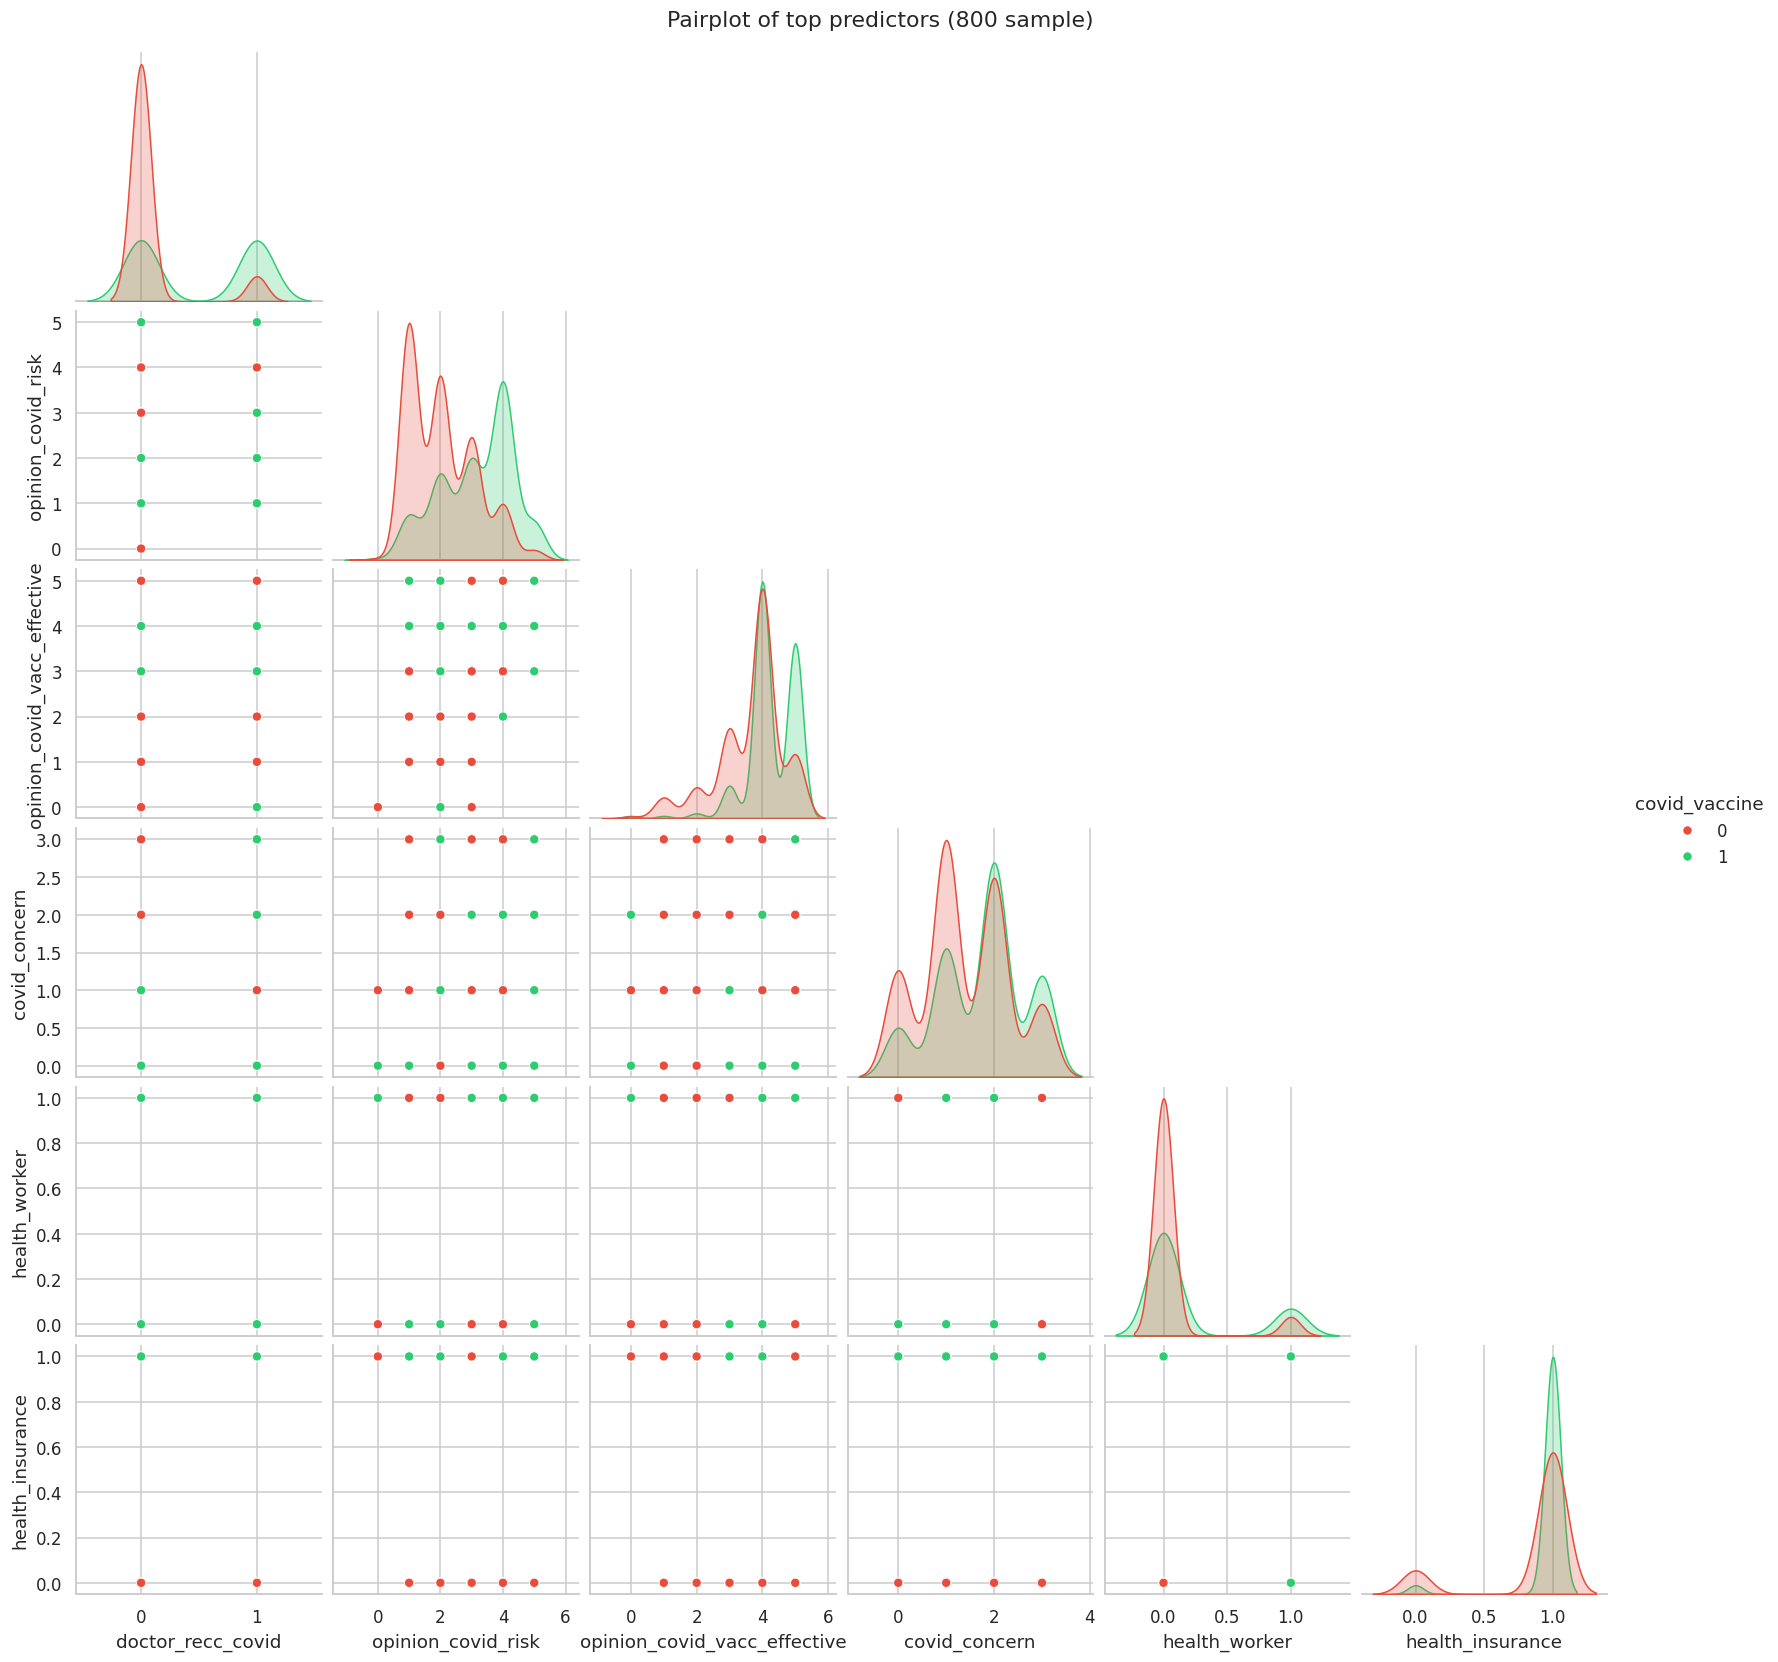

In [ ]:
top_feats = ["covid_vaccine", "doctor_recc_covid",
             "opinion_covid_risk", "opinion_covid_vacc_effective",
             "covid_concern", "health_worker", "health_insurance"]

sns.pairplot(df[top_feats].dropna().sample(800, random_state=42),
             hue="covid_vaccine", palette={0: "#e74c3c", 1: "#2ecc71"},
             diag_kind="kde", corner=True)
plt.suptitle("Pairplot of top predictors (800 sample)", y=1.01)
plt.show()

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Pos rate — train: {y_train.mean():.3f}  test: {y_test.mean():.3f}")

Train: (3804, 29)   Test: (952, 29)
Pos rate — train: 0.327  test: 0.327


In [ ]:
scaler = StandardScaler()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols]  = scaler.transform(X_test[num_cols])

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weights = dict(zip(np.unique(y_train), cw))
print("Computed class weights:", class_weights)
# → {0: ~0.744, 1: ~1.53}

Computed class weights: {np.int64(0): np.float64(0.7426786411557985), np.int64(1): np.float64(1.5301689460981496)}
